# ESE5023 作业二

数据目录：`Assignment2/data`；结果目录：`Assignment2/results`。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

DATA = Path('Assignment2/data')
OUT = Path('Assignment2/results')
OUT.mkdir(parents=True, exist_ok=True)
font = Path('/System/Library/Fonts/Supplemental/Arial Unicode.ttf')
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams.update({'figure.figsize': (9, 3.6), 'figure.dpi': 120,
                     'axes.unicode_minus': False, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.float_format', '{:.2f}'.format)

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()

## 1. 重大地震

读取 NCEI 全列 TSV，去除查询说明行。死亡人数采用 `Deaths`，不与 `Total Deaths` 相加；国家和地区名称沿用数据库。

In [2]:
Sig_Eqs = pd.read_csv(DATA / 'earthquakes.tsv', sep='\t')
Sig_Eqs = Sig_Eqs.dropna(subset=['Year']).copy()
Sig_Eqs['Year'] = Sig_Eqs['Year'].astype(int)
Sig_Eqs = Sig_Eqs[Sig_Eqs['Year'] >= -2150]
print(f'{len(Sig_Eqs)} 条地震记录，{Sig_Eqs.Country.nunique()} 个国家或地区')

6697 条地震记录，162 个国家或地区


### 1.1 死亡人数最多的 20 个国家或地区

**题干：** 统计公元前2150年以来各国地震造成的死亡总人数，输出死亡人数最多的20个国家及人数。

In [3]:
deaths = (Sig_Eqs.groupby('Country')['Deaths'].sum(min_count=1)
          .sort_values(ascending=False).head(20).astype('Int64').rename('死亡人数'))
display(deaths.to_frame())
deaths.to_csv(OUT / '1_1_deaths_top20.csv')

,死亡人数
Country,
CHINA,2139225
TURKEY,1199720
IRAN,1014438
ITALY,492236
HAITI,323484
AZERBAIJAN,319251
SYRIA,289826
JAPAN,242516
ARMENIA,177890


### 1.2 每年 Ms > 3.0 的记录数

**题干：** 用Ms作为震级，统计全球每年震级严格大于3.0的地震次数并绘制时间序列；说明是否存在趋势及原因。

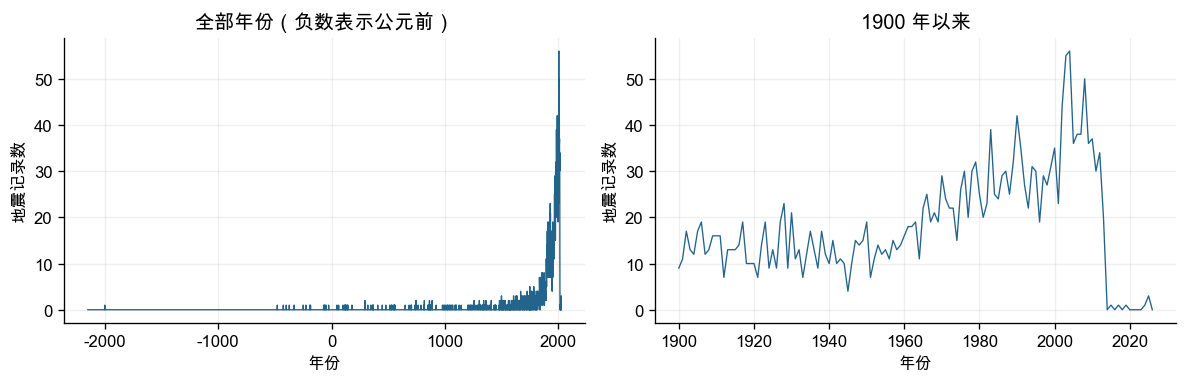

Ms > 3.0 的记录共 3101 条；Ms 缺失 3595 条。


In [4]:
years = pd.Index(range(-2150, Sig_Eqs.Year.max() + 1), name='Year')
years = years[years != 0]
eq_year = (Sig_Eqs[Sig_Eqs.Ms > 3].groupby('Year').size()
           .reindex(years, fill_value=0))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, series, title in zip(axes, [eq_year, eq_year.loc[1900:]],
                           ['全部年份（负数表示公元前）', '1900 年以来']):
    ax.plot(series.index, series.values, lw=0.8, color='#23648c')
    ax.set(xlabel='年份', ylabel='地震记录数', title=title)
    ax.grid(alpha=0.2)
savefig('1_2_earthquakes')
print(f'Ms > 3.0 的记录共 {eq_year.sum()} 条；Ms 缺失 {Sig_Eqs.Ms.isna().sum()} 条。')

近代记录多于古代，但历史记载、观测能力、收录标准和 Ms 资料随年代变化，不能据此认定真实地震频率上升。2026 年资料尚不完整。

### 1.3 各国记录数及最大地震

**题干：** 编写CountEq_LargestEq函数，返回某国公元前2150年以来的地震总次数，以及最大地震的日期和地点；对文件中所有国家调用，按次数降序报告结果。

震级采用 `Mag`，并列时取最早一次；未知月、日记为 `??`。总次数包含震级缺失记录，结果按次数降序排列。另存使用 Ms 的结果。

In [5]:
def CountEq_LargestEq(country, magnitude='Mag'):
    group = Sig_Eqs[Sig_Eqs.Country == country]
    ranked = group.dropna(subset=[magnitude]).sort_values(
        [magnitude, 'Year', 'Mo', 'Dy'], ascending=[False, True, True, True])
    if ranked.empty:
        return pd.Series({'次数': len(group), '最大震级': np.nan,
                          '日期': '未知', '地点': '未知'})
    row = ranked.iloc[0]
    year = f'BC{abs(int(row.Year))}' if row.Year < 0 else str(int(row.Year))
    month = '??' if pd.isna(row.Mo) else f'{int(row.Mo):02d}'
    day = '??' if pd.isna(row.Dy) else f'{int(row.Dy):02d}'
    return pd.Series({'次数': len(group), '最大震级': row[magnitude],
                      '日期': f'{year}-{month}-{day}', '地点': row['Location Name']})

countries = pd.DataFrame({c: CountEq_LargestEq(c) for c in sorted(Sig_Eqs.Country.unique())}).T
countries = countries.sort_values('次数', ascending=False, kind='stable')
countries.index.name = 'Country'
with pd.option_context('display.max_rows', None):
    display(countries)
countries.to_csv(OUT / '1_3_all_countries.csv')

,次数,最大震级,日期,地点
Country,,,,
CHINA,627,8.50,1668-07-25,CHINA: SHANDONG PROVINCE
JAPAN,429,9.10,2011-03-11,JAPAN: HONSHU
INDONESIA,427,9.10,2004-12-26,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
IRAN,385,7.90,856-12-22,"IRAN: DAMGHAN, QUMIS"
TURKEY,359,7.80,1939-12-26,TURKEY: ERZINCAN
ITALY,338,7.50,1915-01-13,"ITALY: MARSICA, AVEZZANO, ABRUZZI"
GREECE,296,8.00,365-07-21,GREECE: CRETE: KNOSSOS
USA,283,9.20,1964-03-28,ALASKA
PHILIPPINES,233,8.70,1897-09-21,"PHILIPPINES: MINDANAO, ZAMBOANGA, SULU, ISABELA"


## 2. 深圳月平均气温

**题干：** 使用宝安机场1998—2022年资料的TMP列，依据ISD说明第10—11页解释数据筛选；绘制月平均气温随时间的变化，并讨论趋势。

拆分 `TMP` 的温度和质量码，剔除 `+9999`，保留质量码 0、1、4、5、9，温度除以 10 转为 °C。去重后，同一时刻取平均，再按 UTC 月份求均值。本文件质量码 9 均为缺测。

数据止于 2022-10-10，图中标记不完整月；趋势拟合使用 1998-01 至 2022-09 的月均距平。

原始 235674 条；无效温度 810 条；有效独立时刻 212131 个。
覆盖 1998-01-01 00:00:00 至 2022-10-10 23:00:00；每月有效时刻 239–745 个。
去季节性后的描述性趋势：0.229 °C/10年


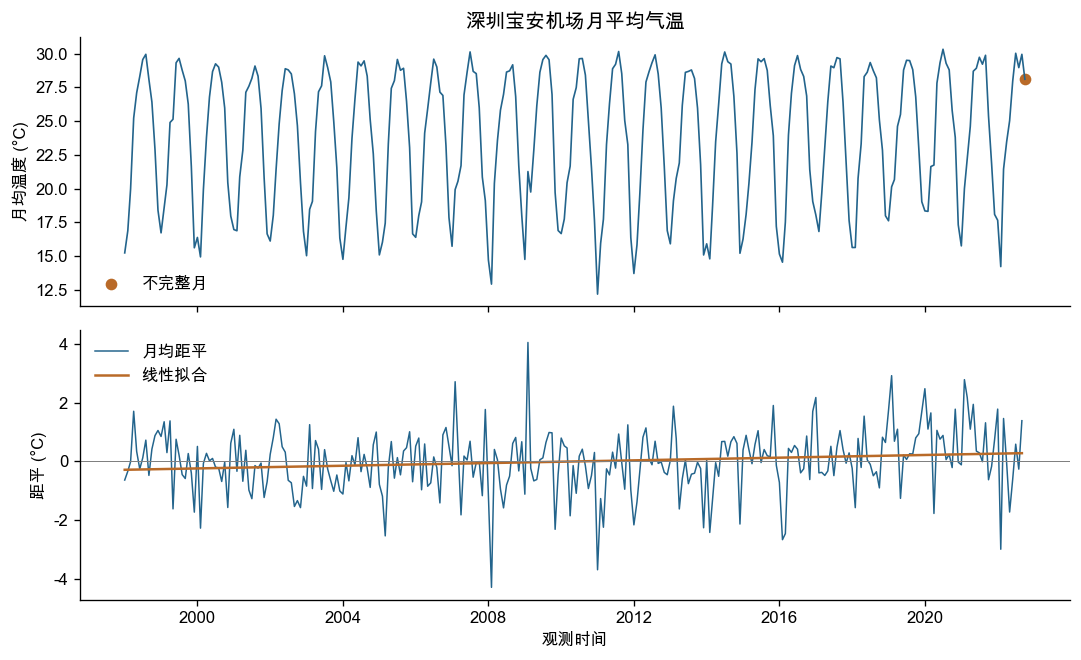

In [6]:
weather = pd.read_csv(DATA / 'Baoan_Weather_1998_2022.csv', usecols=['DATE', 'TMP'])
parts = weather.TMP.str.split(',', expand=True)
raw_temp = pd.to_numeric(parts[0], errors='coerce')
valid = raw_temp.ne(9999) & raw_temp.between(-932, 618) & parts[1].isin(['0','1','4','5','9'])
weather['DATE'] = pd.to_datetime(weather.DATE, errors='coerce')
weather['temp'] = (raw_temp / 10).where(valid)
clean = weather.dropna(subset=['DATE', 'temp']).drop_duplicates(['DATE', 'temp'])
obs = clean.groupby('DATE').temp.mean().sort_index()
monthly = obs.resample('MS').mean()
month_n = obs.resample('MS').count()
full_months = monthly.loc[:'2022-09-01'].dropna()
monthly_clim = full_months.groupby(full_months.index.month).mean()
monthly_anom = full_months - full_months.index.month.map(monthly_clim)
x = full_months.index.year + (full_months.index.month - 1) / 12
slope, intercept = np.polyfit(x, monthly_anom, 1)
print(f'原始 {len(weather)} 条；无效温度 {(~valid).sum()} 条；有效独立时刻 {len(obs)} 个。')
print(f'覆盖 {obs.index.min()} 至 {obs.index.max()}；每月有效时刻 {month_n.min()}–{month_n.max()} 个。')
print(f'去季节性后的描述性趋势：{slope * 10:.3f} °C/10年')
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
axes[0].plot(monthly.index, monthly, color='#23648c', lw=1)
axes[0].scatter(monthly.index[-1], monthly.iloc[-1], color='#b96a28', label='不完整月')
axes[0].set(ylabel='月均温度 (°C)', title='深圳宝安机场月平均气温')
axes[0].legend(frameon=False)
axes[1].plot(full_months.index, monthly_anom, color='#23648c', lw=0.9, label='月均距平')
axes[1].plot(full_months.index, slope * x + intercept, color='#b96a28', label='线性拟合')
axes[1].axhline(0, color='grey', lw=0.6)
axes[1].set(xlabel='观测时间', ylabel='距平 (°C)')
axes[1].legend(frameon=False)
savefig('2_temperature')
monthly.to_csv(OUT / '2_monthly_temperature.csv')

月均温呈冬低夏高的季节变化。去季节性后的线性趋势为 **+0.23 °C/10年**，未作显著性检验。观测密度和日内采样差异可能影响月均值。

## 3. 全球热带气旋

CSV 第二行为单位，仅跳过该行。`NA` 表示北大西洋，读取时保留该代码。`WMO_WIND` 单位为节，各机构平均时长不同，排名使用文件原值。

In [7]:
df = pd.read_csv(DATA / 'ibtracs.ALL.list.v04r00.csv', usecols=range(17),
                 skiprows=[1], keep_default_na=False, na_values=['', ' ', 'NOT_NAMED'],
                 skipinitialspace=True, low_memory=False, parse_dates=['ISO_TIME'])
for col in ['LAT', 'LON', 'WMO_WIND', 'SEASON']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
print(f'{len(df):,} 个数据点，{df.SID.nunique():,} 个 SID；{df.ISO_TIME.min()} 至 {df.ISO_TIME.max()}')
display(df.head(3))

707,177 个数据点，13,664 个 SID；1842-10-25 03:00:00 至 2022-10-13 00:00:00


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 03:00:00,NR,10.90,80.30,NaN,NaN,NaN,main,43,0.00,__________O___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.87,79.83,NaN,NaN,NaN,main,0,0.00,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.84,79.35,NaN,NaN,NaN,main,0,0.00,__________P___


### 3.1–3.2 风速最大的 10 场与 20 场气旋

**题干（3.1）：** 按风暴标识SID分组，依据WMO_WIND找出风速最大的10场气旋，报告其名称NAME。

**题干（3.2）：** 列出风速最强的20场气旋的WMO_WIND值。

按 SID 取各场最大风速，同值按 SID 排序，缺少风速的气旋不参与排名。

In [8]:
storms = (df.groupby('SID').agg(NAME=('NAME', 'first'), YEAR=('SEASON', 'first'),
                              WMO_WIND=('WMO_WIND', 'max')).dropna(subset=['WMO_WIND'])
          .reset_index().sort_values(['WMO_WIND', 'SID'], ascending=[False, True]))
storms['NAME'] = storms.NAME.fillna('未命名')
top20 = storms.head(20).reset_index(drop=True)
top20.index = top20.index + 1
display(top20.head(10))
display(top20[['SID', 'NAME', 'WMO_WIND']])
top20.to_csv(OUT / '3_top20_storms.csv', index_label='排名')

,SID,NAME,YEAR,WMO_WIND
1,2015293N13266,PATRICIA,2015,185.00
2,1980214N11330,ALLEN,1980,165.00
3,1935241N23291,未命名,1935,160.00
4,1988253N12306,GILBERT,1988,160.00
5,1997253N12255,LINDA,1997,160.00
6,2005289N18282,WILMA,2005,160.00
7,2019236N10314,DORIAN,2019,160.00
8,1998295N12284,MITCH,1998,155.00
9,2005261N21290,RITA,2005,155.00
10,2009288N07267,RICK,2009,155.00


,SID,NAME,WMO_WIND
1,2015293N13266,PATRICIA,185.00
2,1980214N11330,ALLEN,165.00
3,1935241N23291,未命名,160.00
4,1988253N12306,GILBERT,160.00
5,1997253N12255,LINDA,160.00
6,2005289N18282,WILMA,160.00
7,2019236N10314,DORIAN,160.00
8,1998295N12284,MITCH,155.00
9,2005261N21290,RITA,155.00
10,2009288N07267,RICK,155.00


### 3.3 各海盆数据点数

**题干：** 按海盆BASIN统计全部数据点的数量。

In [9]:
basins = df.BASIN.fillna('未知').value_counts().rename('数据点数')
display(basins.to_frame())
basins.to_csv(OUT / '3_basins.csv')

,数据点数
BASIN,
WP,236576
SI,160668
NA,124881
SP,67119
EP,62412
NI,55402
SA,119


### 3.4 经纬度六边形密度图

**题干：** 使用数据点的经纬度，绘制六边形分箱图（hexbin）。

跨日期变更线的经度可能超过 180°。先用 `(LON + 180) % 360 - 180` 统一到 [−180°, 180°)，保留有效观测后再作图。

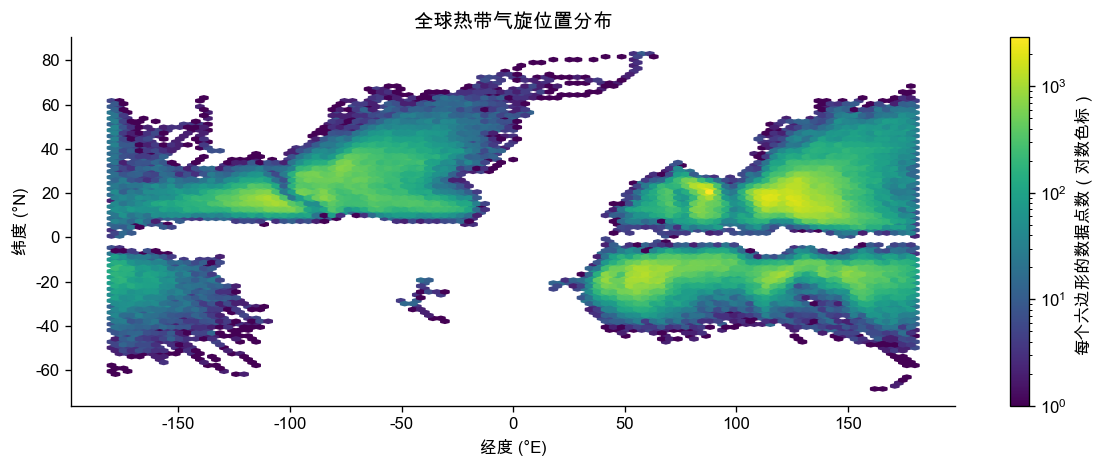

In [10]:
positions = df.loc[df.LAT.between(-90, 90) & df.LON.notna(), ['LAT', 'LON']].copy()
positions['LON'] = (positions.LON + 180) % 360 - 180
plt.figure(figsize=(10, 4))
plt.hexbin(positions.LON, positions.LAT, gridsize=100, mincnt=1, bins='log', cmap='viridis')
plt.colorbar(label='每个六边形的数据点数（对数色标）')
plt.xlabel('经度 (°E)')
plt.ylabel('纬度 (°N)')
plt.title('全球热带气旋位置分布')
savefig('3_4_hexbin')

### 3.5 2018 年山竹路径

**题干：** 找到2018年的台风山竹（Mangkhut），绘制其移动路径。

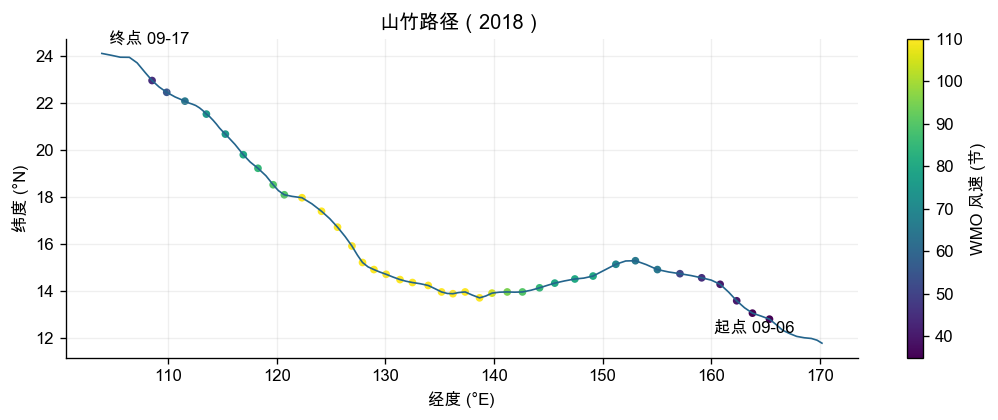

In [11]:
mangkhut = df[(df.NAME == 'MANGKHUT') & (df.SEASON == 2018)].sort_values('ISO_TIME')
plt.plot(mangkhut.LON, mangkhut.LAT, color='#23648c', lw=1)
plt.scatter(mangkhut.LON, mangkhut.LAT, c=mangkhut.WMO_WIND, cmap='viridis', s=13)
plt.colorbar(label='WMO 风速 (节)')
for i, label in [(0, '起点'), (-1, '终点')]:
    row = mangkhut.iloc[i]
    plt.annotate(label + row.ISO_TIME.strftime(' %m-%d'), (row.LON, row.LAT), xytext=(-65, 6) if i == 0 else (4, 6), textcoords='offset points')
plt.xlabel('经度 (°E)')
plt.ylabel('纬度 (°N)')
plt.title('山竹路径（2018）')
plt.grid(alpha=0.2)
savefig('3_5_mangkhut')

### 3.6–3.7 1970 年起 WP、EP 的日数据点数

**题干（3.6）：** 筛选1970年以来西北太平洋WP和东北太平洋EP的数据，后续各小题均使用该子集。

**题干（3.7）：** 绘制每日数据点数量的时间序列。

保留 WP、EP 的轨迹记录，补齐 1970-01-01 至文件结束日的日期，无记录日记 0。

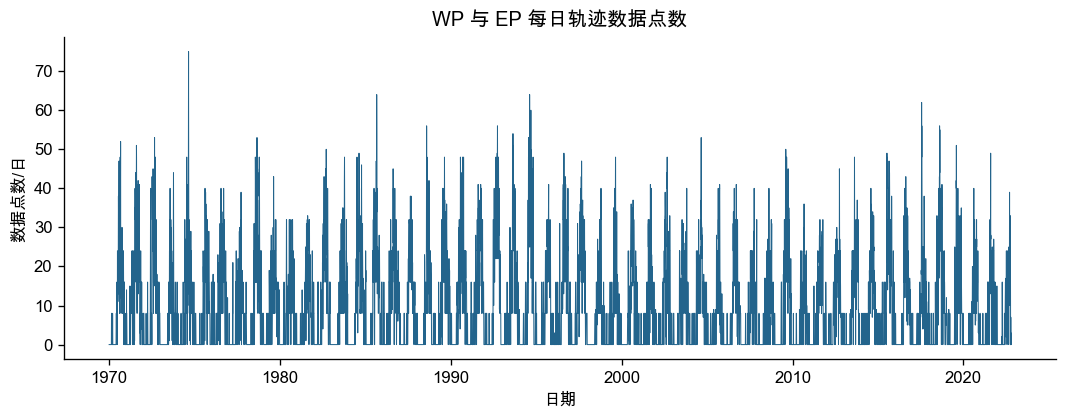

In [12]:
pacific = df[(df.ISO_TIME >= '1970-01-01') & df.BASIN.isin(['WP', 'EP'])].copy()
end = df.ISO_TIME.max().normalize()
daily = (pacific.set_index('ISO_TIME').resample('D').size()
         .reindex(pd.date_range('1970-01-01', end), fill_value=0))
plt.plot(daily.index, daily, color='#23648c', lw=0.6)
plt.xlabel('日期')
plt.ylabel('数据点数/日')
plt.title('WP 与 EP 每日轨迹数据点数')
savefig('3_7_daily')

### 3.8–3.10 日序气候态、日距平及年均距平

**题干（3.8）：** 按一年中的日序（day of year）计算每日数据点数量的气候态。日序从1月1日的1开始。

**题干（3.9）：** 计算每日数据点数量相对于该气候态的距平。

**题干（3.10）：** 将日距平时间序列重采样到年尺度并绘图，指出气旋活动异常的年份。

按日序对 3.6 的全部可用资料求平均，保留第 366 日；闰年 3 月后，同日序对应的月日与平年不同。日距平为当日计数减去对应气候态，年距平取日距平均值。2022 年不参与全年极值比较。

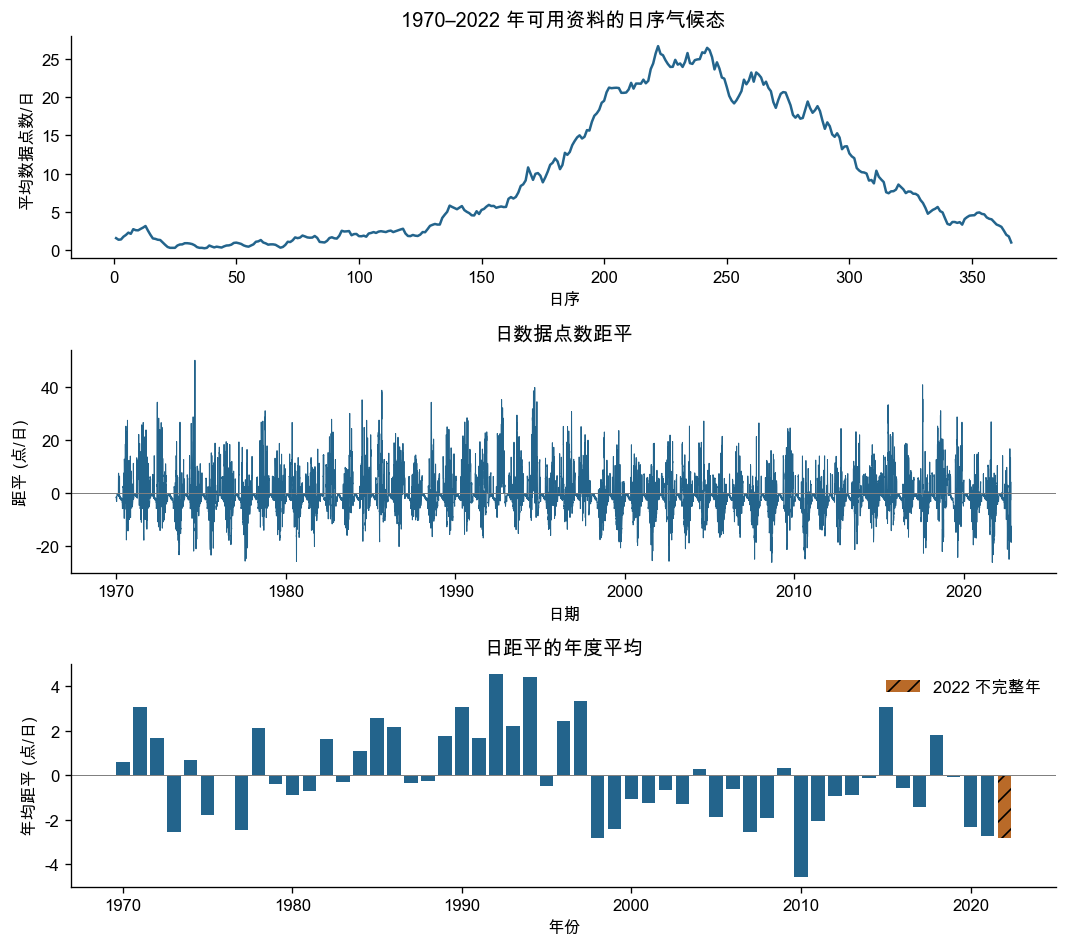

,年均距平
1992,4.54
1994,4.42
1997,3.33
2010,-4.57
1998,-2.83
2021,-2.75


In [13]:
climatology = daily.groupby(daily.index.dayofyear).mean()
anomaly = daily - daily.index.dayofyear.map(climatology)
annual = anomaly.resample('YS').mean()
complete_annual = annual.loc[:'2021']
fig, axes = plt.subplots(3, 1, figsize=(9, 8))
axes[0].plot(climatology.index, climatology, color='#23648c')
axes[0].set(xlabel='日序', ylabel='平均数据点数/日', title='1970–2022 年可用资料的日序气候态')
axes[1].plot(anomaly.index, anomaly, color='#23648c', lw=0.6)
axes[1].axhline(0, color='grey', lw=0.6)
axes[1].set(xlabel='日期', ylabel='距平 (点/日)', title='日数据点数距平')
axes[2].bar(complete_annual.index.year, complete_annual, color='#23648c')
axes[2].bar(2022, annual.iloc[-1], color='#b96a28', hatch='//', label='2022 不完整年')
axes[2].axhline(0, color='grey', lw=0.6)
axes[2].set(xlabel='年份', ylabel='年均距平 (点/日)', title='日距平的年度平均')
axes[2].legend(frameon=False)
savefig('3_8_10_anomalies')
extremes = pd.concat([complete_annual.nlargest(3), complete_annual.nsmallest(3)])
display(extremes.rename('年均距平').to_frame().set_axis(extremes.index.year))
pd.DataFrame({'count': daily, 'anomaly': anomaly}).to_csv(OUT / '3_daily.csv')
annual.to_csv(OUT / '3_annual_anomaly.csv')

1992、1994、1997 年的年均正距平最大；2010、1998、2021 年负距平最明显，数值见上表。2022 年资料不完整，单独标记。计数受风暴数量、持续时间和采样间隔影响。

## 4. 自选数据：纽约拉瓜迪亚机场 2021 年日均气温

**题干（4.1）：** 选择NCEI、AGAGE或课题组提供的带时间信息的CSV、XLS或XLSX数据；读取文件并清理缺失值或低质量记录。

**题干（4.2）：** 选择一个变量，绘制其时间序列。

使用 NCEI GSOD 的 2021 年 CSV，剔除缺测值 9999.9、非数值和观测数不足 4 的记录。`TEMP` 单位为华氏度，按 `(TEMP−32)×5/9` 转为 °C；`TEMP_ATTRIBUTES` 为日均值所用观测数。

原始 365 行，过滤 0 行，缺测 0 天。


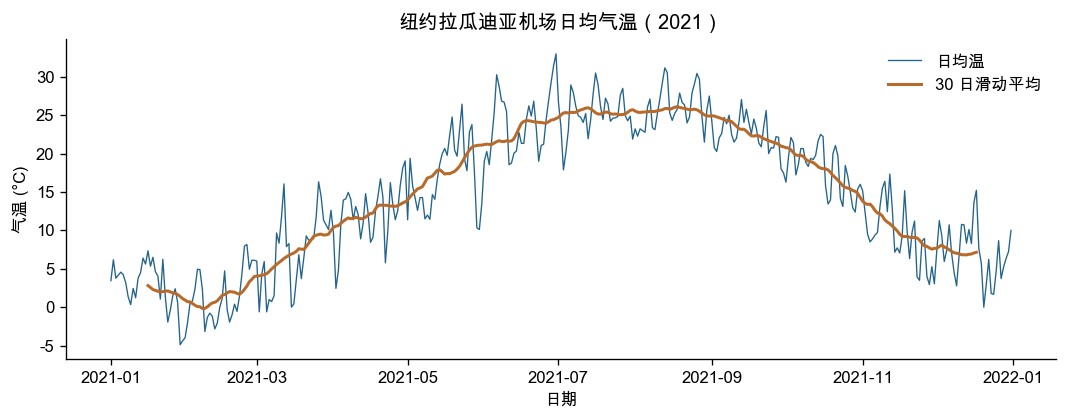

In [14]:
ny = pd.read_csv(DATA / 'new_york_2021.csv', parse_dates=['DATE'])
ny['TEMP'] = pd.to_numeric(ny.TEMP, errors='coerce')
ny['TEMP_ATTRIBUTES'] = pd.to_numeric(ny.TEMP_ATTRIBUTES, errors='coerce')
ny_clean = ny[ny.TEMP.notna() & ny.TEMP.ne(9999.9) & (ny.TEMP_ATTRIBUTES >= 4)].copy()
ny_clean['temp_c'] = (ny_clean.TEMP - 32) * 5 / 9
ny_temp = ny_clean.groupby('DATE').temp_c.mean().reindex(pd.date_range('2021-01-01', '2021-12-31'))
print(f'原始 {len(ny)} 行，过滤 {len(ny)-len(ny_clean)} 行，缺测 {ny_temp.isna().sum()} 天。')
plt.plot(ny_temp.index, ny_temp, color='#23648c', lw=0.8, label='日均温')
plt.plot(ny_temp.index, ny_temp.rolling(30, center=True, min_periods=30).mean(),
         color='#b96a28', lw=1.8, label='30 日滑动平均')
plt.xlabel('日期')
plt.ylabel('气温 (°C)')
plt.title('纽约拉瓜迪亚机场日均气温（2021）')
plt.legend(frameon=False)
savefig('4_new_york')

### 4.3 描述统计

**题干：** 对该变量进行至少5项简单统计检查，并报告发现。

In [15]:
ny_stats = pd.Series({'有效天数': ny_temp.count(), '均值 (°C)': ny_temp.mean(),
                      '中位数 (°C)': ny_temp.median(), '样本标准差 (°C)': ny_temp.std(),
                      '最小值 (°C)': ny_temp.min(), '最大值 (°C)': ny_temp.max(),
                      '四分位距 (°C)': ny_temp.quantile(.75)-ny_temp.quantile(.25),
                      '低于 0°C 天数': (ny_temp < 0).sum(), '高于 25°C 天数': (ny_temp > 25).sum()})
display(ny_stats.to_frame('结果'))
print(f'最冷日：{ny_temp.idxmin():%Y-%m-%d}；最热日：{ny_temp.idxmax():%Y-%m-%d}')
ny_stats.to_csv(OUT / '4_statistics.csv')

,结果
有效天数,365.00
均值 (°C),14.50
中位数 (°C),14.44
样本标准差 (°C),9.18
最小值 (°C),-4.89
最大值 (°C),33.00
四分位距 (°C),16.11
低于 0°C 天数,19.00
高于 25°C 天数,48.00


最冷日：2021-01-29；最热日：2021-06-30


全年日均温均值为 14.50°C，中位数为 14.44°C，样本标准差为 9.18°C；低于 0°C 有 19 天，高于 25°C 有 48 天。气温呈冬低夏高的季节变化，一年资料不足以判断长期趋势。

## 补充结果

1.3 的 Ms 结果另存 CSV。下表列出 3.2 按原始观测排序的前 20 条，同一 SID 可重复。

In [16]:
countries_ms = pd.DataFrame({c: CountEq_LargestEq(c, 'Ms') for c in countries.index}).T
countries_ms.index.name = 'Country'
countries_ms.to_csv(OUT / '1_3_all_countries_Ms.csv')
record_top20 = df.nlargest(20, 'WMO_WIND')[['SID', 'NAME', 'ISO_TIME', 'WMO_WIND']]
display(record_top20.reset_index(drop=True))
record_top20.to_csv(OUT / '3_2_top20_observations.csv', index=False)

,SID,NAME,ISO_TIME,WMO_WIND
0,2015293N13266,PATRICIA,2015-10-23 12:00:00,185.00
1,2015293N13266,PATRICIA,2015-10-23 06:00:00,180.00
2,2015293N13266,PATRICIA,2015-10-23 18:00:00,180.00
3,1980214N11330,ALLEN,1980-08-07 18:00:00,165.00
4,1935241N23291,NaN,1935-09-03 00:00:00,160.00
5,1935241N23291,NaN,1935-09-03 02:00:00,160.00
6,1935241N23291,NaN,1935-09-03 06:00:00,160.00
7,1988253N12306,GILBERT,1988-09-14 00:00:00,160.00
8,1997253N12255,LINDA,1997-09-12 06:00:00,160.00
9,2005289N18282,WILMA,2005-10-19 12:00:00,160.00


## 数据来源

- [作业要求](https://zhu-group.github.io/ese5023/Assignment_02.html)
- [重大地震数据库](https://www.ngdc.noaa.gov/hazel/view/hazards/earthquake/event-data)，全列 TSV，2026-10-26 下载。
- [宝安机场数据](https://zhu-group.github.io/ese5023/download/Baoan_Weather_1998_2022.zip)；[ISD 格式说明，第 10–11 页](https://zhu-group.github.io/ese5023/download/isd-format-document.pdf)。
- [课程 IBTrACS v04r00 数据](https://zhu-group.github.io/ese5023/download/ibtracs.ALL.list.v04r00.zip)；[变量说明](https://www.ncei.noaa.gov/sites/default/files/2021-07/IBTrACS_v04_column_documentation.pdf)。
- [拉瓜迪亚站 2021 年 CSV](https://www.ncei.noaa.gov/data/global-summary-of-the-day/access/2021/72503014732.csv)；[GSOD 格式说明](https://www.ncei.noaa.gov/data/global-summary-of-the-day/doc/readme.txt)。

In [17]:
summary = {'earthquakes': len(Sig_Eqs), 'countries': len(countries),
           'ms_count': int(eq_year.sum()), 'ms_missing': int(Sig_Eqs.Ms.isna().sum()),
           'weather_raw': len(weather), 'weather_invalid': int((~valid).sum()),
           'weather_times': len(obs), 'temperature_trend_per_decade': float(slope*10),
           'weather_first': str(obs.index.min()), 'weather_last': str(obs.index.max()),
           'storm_points': len(df), 'storm_count': int(df.SID.nunique()),
           'pacific_points': len(pacific), 'baseline_peak_day': int(climatology.idxmax()),
           'positive_years': {str(k.year): float(v) for k,v in complete_annual.nlargest(3).items()},
           'negative_years': {str(k.year): float(v) for k,v in complete_annual.nsmallest(3).items()},
           'ny_coldest_date': str(ny_temp.idxmin().date()), 'ny_hottest_date': str(ny_temp.idxmax().date()),
           'ny_removed': len(ny)-len(ny_clean)}
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

742